<a href="https://colab.research.google.com/github/USERNAME/Grokking-Deep-Learning/blob/main/08_regularization-and-batching.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 8: Learning Signal and Ignoring Noise
## Introduction to regularization and batching

**Companion notebook for *Grokking Deep Learning* (Andrew W. Trask, Manning)**

This notebook reproduces the Chapter 8 experiments on MNIST (three-layer network → overfitting → dropout → mini-batches) and adds a few plots and small experiments of my own. The full notebook trains several networks, so expect roughly **3 to 5 minutes** in total on Colab.

---
## Three-layer network on MNIST

In earlier chapters you saw that hidden layers can *create* intermediate correlation. The new question: **how do we know the network is learning *good* correlation?** Recall the experiment where one weight was frozen: the other weights adjusted until the error was 0, even though the frozen input might have been important in the real world. The network had found a way to fit the training data while ignoring something useful. That is **overfitting**, the "archnemesis" of neural networks: the more powerful the network (more layers and weights), the more prone it is.

Chapter 8 studies **regularization**, the toolbox for fighting it, using the strongest network we have (three layers, relu hidden layer) on a hard task (MNIST digit classification).

### Loading MNIST
The book calls `keras.datasets.mnist` (preinstalled on Colab). The cell below does exactly that, and **falls back to downloading the same MNIST data from a public GitHub mirror** if Keras isn't available, so the notebook also runs outside Colab. As in the book, we train on only the **first 1,000 images** and test on the standard **10,000 test images**. I also keep images 1,000–1,999 as a *validation set* (used for early stopping later).

In [1]:
import sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt

def load_mnist():
    try:
        from keras.datasets import mnist                      # what the book uses
        (x_train, y_train), (x_test, y_test) = mnist.load_data()
        x_train = x_train.reshape(len(x_train), 784) / 255
        x_test  = x_test.reshape(len(x_test), 784) / 255
    except Exception:                                         # fallback: same dataset from a GitHub mirror
        import gzip, pickle, os, urllib.request
        url = "https://raw.githubusercontent.com/mnielsen/neural-networks-and-deep-learning/master/data/mnist.pkl.gz"
        if not os.path.exists("mnist.pkl.gz"):
            urllib.request.urlretrieve(url, "mnist.pkl.gz")
        with gzip.open("mnist.pkl.gz", "rb") as f, warnings.catch_warnings():
            warnings.simplefilter("ignore")
            train, valid, test = pickle.load(f, encoding="latin1")
        x_train, y_train = train[0].astype("float64"), train[1]
        x_test,  y_test  = test[0].astype("float64"),  test[1]

    def one_hot(y):
        out = np.zeros((len(y), 10))
        out[np.arange(len(y)), y] = 1
        return out

    images,      labels      = x_train[0:1000],    one_hot(y_train[0:1000])
    val_images,  val_labels  = x_train[1000:2000], one_hot(y_train[1000:2000])
    test_images, test_labels = x_test,             one_hot(y_test)
    return images, labels, val_images, val_labels, test_images, test_labels

images, labels, val_images, val_labels, test_images, test_labels = load_mnist()
print("train :", images.shape, labels.shape)
print("val   :", val_images.shape)
print("test  :", test_images.shape, test_labels.shape)
print("first labels:", labels[:10].argmax(axis=1))

train : (1000, 784) (1000, 10)
val   : (1000, 784)
test  : (10000, 784) (10000, 10)
first labels: [5 0 4 1 9 2 1 3 1 4]


Let's look at a few of the training images, so we know what the network is learning from.

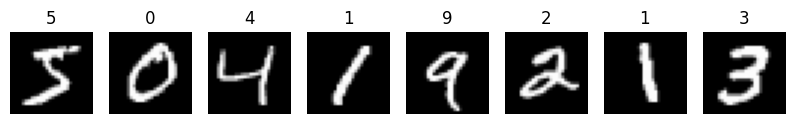

In [2]:
fig, axes = plt.subplots(1, 8, figsize=(10, 1.6))
for ax, img, lab in zip(axes, images[:8], labels[:8].argmax(axis=1)):
    ax.imshow(img.reshape(28, 28), cmap="gray"); ax.set_title(str(lab)); ax.axis("off")
plt.show()

A helper to evaluate any network on a whole dataset **at once** (the book loops image by image; the numbers are identical, this is just faster):

In [3]:
relu       = lambda x: (x >= 0) * x
relu2deriv = lambda x: x >= 0

def evaluate(w01, w12, X, Y):
    layer_2 = relu(X.dot(w01)).dot(w12)
    err = np.sum((Y - layer_2) ** 2) / len(X)
    acc = np.mean(layer_2.argmax(axis=1) == Y.argmax(axis=1))
    return err, acc

Now the book's training loop: one image at a time (stochastic gradient descent), 40 hidden nodes, 350 iterations. We log train/validation/test numbers every 10 iterations. *(About 30 to 60 seconds.)*

In [4]:
np.random.seed(1)
alpha, iterations, hidden_size, pixels_per_image, num_labels = (0.005, 350, 40, 784, 10)

weights_0_1 = 0.2 * np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

log_plain = {"it": [], "train_err": [], "train_acc": [], "val_acc": [], "test_err": [], "test_acc": []}

for j in range(iterations):
    error, correct_cnt = (0.0, 0)
    for i in range(len(images)):
        layer_0 = images[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        layer_2 = np.dot(layer_1, weights_1_2)

        error += np.sum((labels[i:i+1] - layer_2) ** 2)
        correct_cnt += int(np.argmax(layer_2) == np.argmax(labels[i:i+1]))

        layer_2_delta = (labels[i:i+1] - layer_2)
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)

        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    if j % 10 == 0 or j == iterations - 1:
        te, ta = evaluate(weights_0_1, weights_1_2, test_images, test_labels)
        _,  va = evaluate(weights_0_1, weights_1_2, val_images, val_labels)
        for k, v in zip(log_plain, (j, error / len(images), correct_cnt / len(images), va, te, ta)):
            log_plain[k].append(v)
        print(f"I:{j:3d} Train-Err:{error/len(images):.3f} Train-Acc:{correct_cnt/len(images):.3f}  "
              f"Test-Err:{te:.3f} Test-Acc:{ta:.4f}")

I:  0 Train-Err:0.723 Train-Acc:0.537  Test-Err:0.602 Test-Acc:0.6488


I: 10 Train-Err:0.312 Train-Acc:0.900  Test-Err:0.420 Test-Acc:0.8116


I: 20 Train-Err:0.261 Train-Acc:0.930  Test-Err:0.414 Test-Acc:0.8111


I: 30 Train-Err:0.233 Train-Acc:0.946  Test-Err:0.417 Test-Acc:0.8064


I: 40 Train-Err:0.216 Train-Acc:0.956  Test-Err:0.427 Test-Acc:0.8020


...

I:310 Train-Err:0.112 Train-Acc:0.999  Test-Err:0.621 Test-Acc:0.7165


I:320 Train-Err:0.111 Train-Acc:0.999  Test-Err:0.629 Test-Acc:0.7145


I:330 Train-Err:0.110 Train-Acc:0.999  Test-Err:0.636 Test-Acc:0.7125


I:340 Train-Err:0.109 Train-Acc:1.000  Test-Err:0.645 Test-Acc:0.7103


I:349 Train-Err:0.109 Train-Acc:1.000  Test-Err:0.653 Test-Acc:0.7077


---
## Well, that was easy

The network predicts all 1,000 training images perfectly (**train accuracy 100%**). In one sense that is a victory: it learned to map every training image to its label by nudging weights a little after each prediction.

But the question that matters is *how well does it do on images it has never seen?* The held-out 10,000 test images answer it. The last line printed above is the **test accuracy**: it simulates real-world use, where the network only ever sees new images. That is the score that counts.

---
## Memorization vs. generalization

Memorizing 1,000 images is easier than generalizing to all images. A network trained to perfection on specific inputs is only guaranteed to work on inputs that look nearly identical to what it saw. Otherwise it behaves almost randomly. A network that only works on data you already have labels for is pointless, because you already know those answers.

**A clue to better networks** is in the log above: print/plot training and testing accuracy side by side.

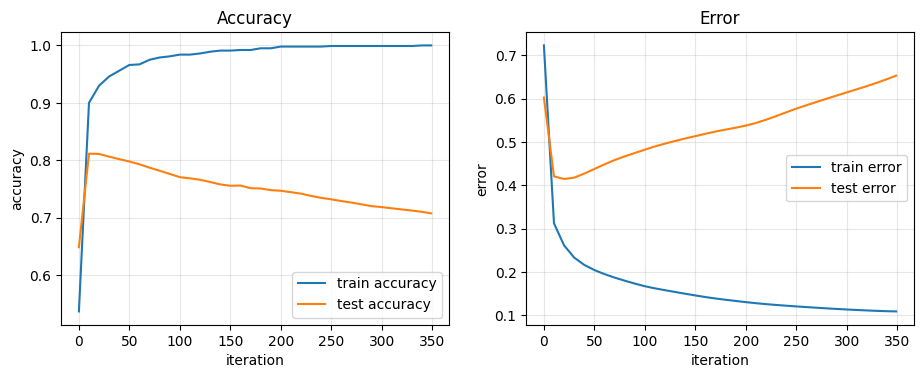

best test accuracy 0.8116 at iteration 10
final test accuracy 0.7077 at iteration 349  (train accuracy 1.000)


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(log_plain["it"], log_plain["train_acc"], label="train accuracy")
ax[0].plot(log_plain["it"], log_plain["test_acc"],  label="test accuracy")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("accuracy"); ax[0].set_title("Accuracy"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(log_plain["it"], log_plain["train_err"], label="train error")
ax[1].plot(log_plain["it"], log_plain["test_err"],  label="test error")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("error"); ax[1].set_title("Error"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.show()

best = int(np.argmax(log_plain["test_acc"]))
print(f"best test accuracy {log_plain['test_acc'][best]:.4f} at iteration {log_plain['it'][best]}")
print(f"final test accuracy {log_plain['test_acc'][-1]:.4f} at iteration {log_plain['it'][-1]}  (train accuracy {log_plain['train_acc'][-1]:.3f})")

---
## Overfitting in neural networks

**Neural networks can get worse if you train them too much.** Test accuracy rises for the first ~10 to 20 iterations, then *slowly decreases* while training accuracy keeps improving.

The book's analogy: pressing three-pronged forks into clay hundreds of times produces a mold that fits only forks with exactly three prongs. A four-pronged fork is still a fork but doesn't fit. The clay overfit to the particular forks it was shaped on. Likewise the weights form a high-dimensional "shape" that molds itself around the training data, including its quirks.

> **Overfitting** = the network learned the *noise* in the dataset instead of making decisions from the true *signal*.

**My demo: how much can the network memorize?** If it can fit **random** labels (pure noise, no signal at all), then high training accuracy by itself proves nothing.

In [6]:
rng = np.random.RandomState(0)
random_labels = np.zeros((len(images), 10))
random_labels[np.arange(len(images)), rng.randint(0, 10, len(images))] = 1

def train_simple(X, Y, hidden=100, alpha=0.005, iters=100, seed=1):
    r = np.random.RandomState(seed)
    w01 = 0.2 * r.random_sample((784, hidden)) - 0.1
    w12 = 0.2 * r.random_sample((hidden, 10)) - 0.1
    for _ in range(iters):
        for i in range(len(X)):
            l0 = X[i:i+1]; l1 = relu(l0.dot(w01)); l2 = l1.dot(w12)
            d2 = Y[i:i+1] - l2; d1 = d2.dot(w12.T) * relu2deriv(l1)
            w12 += alpha * l1.T.dot(d2); w01 += alpha * l0.T.dot(d1)
    return w01, w12

w01_r, w12_r = train_simple(images, random_labels)
_, tr = evaluate(w01_r, w12_r, images, random_labels)
_, te = evaluate(w01_r, w12_r, test_images, test_labels)
print(f"accuracy on the random training labels : {tr:.2%}   (pure guessing would be ~10%)")
print(f"accuracy on real test labels           : {te:.2%}")

accuracy on the random training labels : 71.00%   (pure guessing would be ~10%)
accuracy on real test labels           : 8.03%


The network happily fits labels that have **no pattern at all**, far above the 10% you'd get by guessing, yet it knows nothing useful about digits. Fitting the training set is not evidence of learning; only performance on **unseen data** is.

---
## Where overfitting comes from

With a single fork pressed once into thick clay, the mold is only a rough fork shape, compatible with three- *and* four-pronged forks. The more imprints, the more detail it captures, and the worse it gets at forks that differ even slightly.

In images, that "detail" is **noise**: everything that makes a particular picture unique beyond the essence of the class (a pillow behind a dog, the dark middle of a silhouette). In reality it is more nuanced, but the idea is that *the fine-grained detail is where overfitting hides, while the signal (general shape, edges) is coarser*. One way to ignore fine detail is simply to stop training before the network learns it.

---
## The simplest regularization: Early stopping

**Stop training when the network starts getting worse.** It is the cheapest form of regularization and can be very effective.

> **Regularization**: a subset of methods used to encourage generalization in learned models, often by making it harder for the model to learn the fine-grained details of the training data.

*How do you know when to stop?* Only by running on data that isn't in the training set. But if you use the **test** set to decide, you can overfit to the test set. So use a separate **validation set** to control training and keep the test set for the final score. (The validation split is my addition; the book just describes the idea.)

validation accuracy peaks at iteration 10  (val acc = 0.8120)
-> test accuracy at that iteration (early stopping): 0.8116
-> test accuracy if we trained to the end         : 0.7077


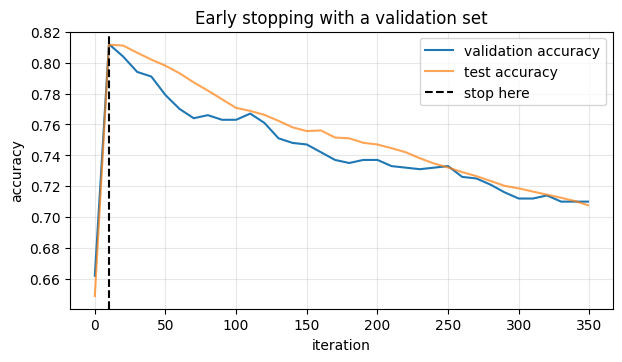

In [7]:
best_val = int(np.argmax(log_plain["val_acc"]))
print(f"validation accuracy peaks at iteration {log_plain['it'][best_val]}  (val acc = {log_plain['val_acc'][best_val]:.4f})")
print(f"-> test accuracy at that iteration (early stopping): {log_plain['test_acc'][best_val]:.4f}")
print(f"-> test accuracy if we trained to the end         : {log_plain['test_acc'][-1]:.4f}")

plt.figure(figsize=(7, 3.6))
plt.plot(log_plain["it"], log_plain["val_acc"],  label="validation accuracy")
plt.plot(log_plain["it"], log_plain["test_acc"], label="test accuracy", alpha=.7)
plt.axvline(log_plain["it"][best_val], color="k", ls="--", label="stop here")
plt.xlabel("iteration"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=.3); plt.title("Early stopping with a validation set"); plt.show()

---
## Industry standard regularization: Dropout

**Method: randomly turn off neurons (set them to 0) during training**, usually along with their deltas in backpropagation. The network trains on random sub-networks.

*Why it works (oversimplified):* **dropout makes a big network act like a little one**, and little networks can't overfit much, because they lack the *capacity* to latch onto fine details. Clay made of dime-sized stones can't take a detailed fork imprint; clay made of fine sand can. Big networks are "fine sand". Turning off nodes at random uses only a few big "stones" at a time, yet over millions of different sub-networks the whole network keeps its expressive power.

---
## Why dropout works: Ensembling works

Neural networks start out random, so each one learns a little differently. Two key facts:

1. Large unregularized networks tend to overfit to noise, but **not to the same noise**: they stop once they can tell all the training images apart, and each started somewhere different.
2. Even so, networks all learn the **biggest, broadest features first**.

So if you train many networks and let them vote, their different mistakes (noise) tend to cancel and the shared knowledge (signal) remains. Dropout is a cheap way of training and averaging a huge number of sub-networks at once.

**My demo: a real ensemble.** Train 5 plain networks from different random starts (stopping near their test-accuracy peak) and average their predictions.

In [8]:
def predict(w, X): return relu(X.dot(w[0])).dot(w[1])

nets = [train_simple(images, labels, hidden=40, iters=40, seed=s) for s in range(5)]
preds = [predict(n, test_images) for n in nets]
single = [np.mean(p.argmax(1) == test_labels.argmax(1)) for p in preds]
ens = np.mean(sum(preds).argmax(1) == test_labels.argmax(1))
print("single networks :", [round(float(a), 4) for a in single])
print("average of them :", round(float(np.mean(single)), 4))
print("5-net ensemble  :", round(float(ens), 4))

single networks : [0.8207, 0.8032, 0.8036, 0.8097, 0.8041]
average of them : 0.8083
5-net ensemble  : 0.8444


The ensemble beats every individual network: the networks' idiosyncratic mistakes cancel while what they have in common survives.

---
## Dropout in code

Dropout is a **three-line change**: build a random 0/1 mask the shape of the layer, multiply the layer by it (and by 2), and multiply the layer's delta by the same mask.

- `dropout_mask = np.random.randint(2, size=layer_1.shape)` is a **50% Bernoulli** mask: each value is 1 half the time, 0 the other half.
- `layer_1 *= dropout_mask * 2`: the `* 2` compensates for losing half the signal. `layer_2` takes a *sum* over `layer_1`, so with half the nodes off the sum would halve. Multiplying by `1 / (fraction kept)` = 2 keeps the "volume" the same as at test time, when dropout is off.
- `layer_1_delta *= dropout_mask`: turned-off nodes also get no update.

In [9]:
# A tiny look at what the mask does
np.random.seed(0)
layer_1_demo = np.array([[0.4, 1.2, 0.0, 0.9, 0.3, 0.7, 1.1, 0.5]])
mask = np.random.randint(2, size=layer_1_demo.shape)
dropped = layer_1_demo * mask * 2

print("layer_1        :", layer_1_demo)
print("dropout_mask   :", mask)
print("after mask * 2 :", dropped)

# On average the weighted sum is preserved:
w = np.random.randn(8, 1)
sums = [(layer_1_demo * np.random.randint(2, size=(1, 8)) * 2).dot(w)[0, 0] for _ in range(20000)]
print(f"\nsum without dropout = {layer_1_demo.dot(w)[0,0]:.3f},  mean of sums WITH dropout x2 = {np.mean(sums):.3f}")

layer_1        : [[0.4 1.2 0.  0.9 0.3 0.7 1.1 0.5]]
dropout_mask   : [[0 1 1 0 1 1 1 1]]
after mask * 2 : [[0.  2.4 0.  0.  0.6 1.4 2.2 1. ]]



sum without dropout = 0.580,  mean of sums WITH dropout x2 = 0.571


Now the full dropout network from the book: 100 hidden nodes, 300 iterations, 50% dropout on the hidden layer. *(About 1 minute.)*

In [10]:
np.random.seed(1)
alpha, iterations, hidden_size = (0.005, 300, 100)
pixels_per_image, num_labels = (784, 10)

weights_0_1 = 0.2 * np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

log_drop = {"it": [], "train_acc": [], "test_acc": []}

for j in range(iterations):
    error, correct_cnt = (0.0, 0)
    for i in range(len(images)):
        layer_0 = images[i:i+1]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2
        layer_2 = np.dot(layer_1, weights_1_2)

        error += np.sum((labels[i:i+1] - layer_2) ** 2)
        correct_cnt += int(np.argmax(layer_2) == np.argmax(labels[i:i+1]))

        layer_2_delta = (labels[i:i+1] - layer_2)
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
        layer_1_delta *= dropout_mask

        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    if j % 10 == 0 or j == iterations - 1:
        te, ta = evaluate(weights_0_1, weights_1_2, test_images, test_labels)
        log_drop["it"].append(j); log_drop["train_acc"].append(correct_cnt / len(images)); log_drop["test_acc"].append(ta)
        print(f"I:{j:3d} Test-Err:{te:.3f} Test-Acc:{ta:.4f}  Train-Err:{error/len(images):.3f} Train-Acc:{correct_cnt/len(images):.3f}")

I:  0 Test-Err:0.642 Test-Acc:0.6330  Train-Err:0.891 Train-Acc:0.413


I: 10 Test-Err:0.459 Test-Acc:0.7873  Train-Err:0.472 Train-Acc:0.764


I: 20 Test-Err:0.416 Test-Acc:0.8138  Train-Err:0.431 Train-Acc:0.808


I: 30 Test-Err:0.421 Test-Acc:0.8119  Train-Err:0.416 Train-Acc:0.811


I: 40 Test-Err:0.420 Test-Acc:0.8110  Train-Err:0.413 Train-Acc:0.828


...

I:260 Test-Err:0.390 Test-Acc:0.8207  Train-Err:0.322 Train-Acc:0.898


I:270 Test-Err:0.382 Test-Acc:0.8196  Train-Err:0.313 Train-Acc:0.904


I:280 Test-Err:0.397 Test-Acc:0.8209  Train-Err:0.318 Train-Acc:0.901


I:290 Test-Err:0.400 Test-Acc:0.8180  Train-Err:0.303 Train-Acc:0.911


I:299 Test-Err:0.393 Test-Acc:0.8225  Train-Err:0.302 Train-Acc:0.917


---
## Dropout evaluated on MNIST

Without dropout, test accuracy peaked around 81% and then fell to roughly 71%. With dropout the picture is different:

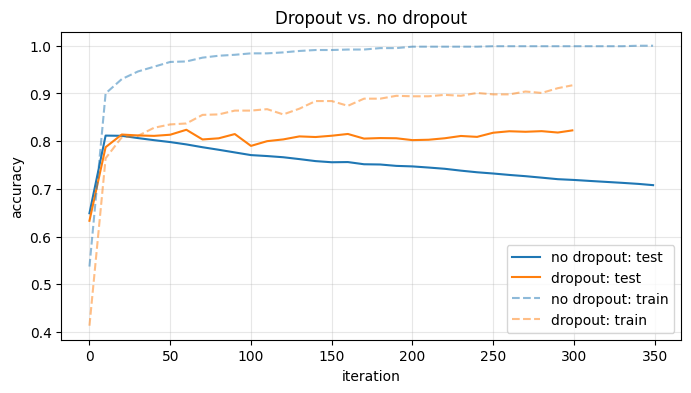

no dropout : peak test 0.8116, final test 0.7077, final train 1.000
dropout    : peak test 0.8238, final test 0.8225, final train 0.917


In [11]:
plt.figure(figsize=(8, 4))
plt.plot(log_plain["it"], log_plain["test_acc"], label="no dropout: test")
plt.plot(log_drop["it"],  log_drop["test_acc"],  label="dropout: test")
plt.plot(log_plain["it"], log_plain["train_acc"], "--", color="C0", alpha=.5, label="no dropout: train")
plt.plot(log_drop["it"],  log_drop["train_acc"],  "--", color="C1", alpha=.5, label="dropout: train")
plt.xlabel("iteration"); plt.ylabel("accuracy"); plt.title("Dropout vs. no dropout"); plt.legend(); plt.grid(alpha=.3); plt.show()

print(f"no dropout : peak test {max(log_plain['test_acc']):.4f}, final test {log_plain['test_acc'][-1]:.4f}, final train {log_plain['train_acc'][-1]:.3f}")
print(f"dropout    : peak test {max(log_drop['test_acc']):.4f}, final test {log_drop['test_acc'][-1]:.4f}, final train {log_drop['train_acc'][-1]:.3f}")

Dropout (a) reaches a slightly **higher peak**, (b) **doesn't collapse** as training continues, and (c) **slows down training accuracy**, which no longer shoots to 100%. That is the point: **dropout is noise.** It makes fitting the training data harder, like running a marathon with weights on your legs: you train for something tougher and run faster when the weights come off at test time.

---
## Batch gradient descent

Instead of updating after **each** image, update after each **batch** of examples using the **average** of their weight updates (here 100 images). Two benefits:

1. **Speed**: each `np.dot` handles 100 examples at once, which CPUs do very efficiently.
2. **Smoother learning**: a single example's weight update is noisy; averaging 100 of them cancels much of that noise. The book's analogy is finding a city with a wobbly compass. One reading sends you off course; the average of 100 readings points roughly the right way, so you can take **bigger steps** (i.e. use a larger `alpha`).

Typical batch sizes range from about 8 up to 256.

> **A note on the book's listing.** The printed code says `alpha = 0.001`, but the text says alpha is *"20 times larger than before"* (before: 0.005, so 0.1), and only `alpha = 0.1` reproduces the output printed in the book (e.g. test accuracy ≈ 0.383 after the first iteration). With `0.001` the network barely learns in 300 iterations. I use **0.1** here. I also count correct predictions for the whole batch at once, instead of with an inner loop.

In [12]:
np.random.seed(1)
batch_size = 100
alpha, iterations = (0.1, 300)
pixels_per_image, num_labels, hidden_size = (784, 10, 100)

weights_0_1 = 0.2 * np.random.random((pixels_per_image, hidden_size)) - 0.1
weights_1_2 = 0.2 * np.random.random((hidden_size, num_labels)) - 0.1

log_batch = {"it": [], "train_acc": [], "test_acc": []}
t0 = time.time()

for j in range(iterations):
    error, correct_cnt = (0.0, 0)
    for i in range(int(len(images) / batch_size)):
        batch_start, batch_end = ((i * batch_size), ((i + 1) * batch_size))

        layer_0 = images[batch_start:batch_end]
        layer_1 = relu(np.dot(layer_0, weights_0_1))
        dropout_mask = np.random.randint(2, size=layer_1.shape)
        layer_1 *= dropout_mask * 2
        layer_2 = np.dot(layer_1, weights_1_2)

        error += np.sum((labels[batch_start:batch_end] - layer_2) ** 2)
        correct_cnt += int(np.sum(np.argmax(layer_2, axis=1) == np.argmax(labels[batch_start:batch_end], axis=1)))

        layer_2_delta = (labels[batch_start:batch_end] - layer_2) / batch_size   # average over the batch
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)
        layer_1_delta *= dropout_mask

        weights_1_2 += alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 += alpha * layer_0.T.dot(layer_1_delta)

    if j % 10 == 0 or j == iterations - 1:
        te, ta = evaluate(weights_0_1, weights_1_2, test_images, test_labels)
        log_batch["it"].append(j); log_batch["train_acc"].append(correct_cnt / len(images)); log_batch["test_acc"].append(ta)
        print(f"I:{j:3d} Test-Err:{te:.3f} Test-Acc:{ta:.4f}  Train-Err:{error/len(images):.3f} Train-Acc:{correct_cnt/len(images):.3f}")
print(f"\n300 iterations took {time.time() - t0:.1f} s (the one-image-at-a-time dropout run above took many times longer)")

I:  0 Test-Err:0.816 Test-Acc:0.3826  Train-Err:1.271 Train-Acc:0.161


I: 10 Test-Err:0.569 Test-Acc:0.7179  Train-Err:0.592 Train-Acc:0.671


I: 20 Test-Err:0.509 Test-Acc:0.7572  Train-Err:0.530 Train-Acc:0.726


I: 30 Test-Err:0.483 Test-Acc:0.7810  Train-Err:0.498 Train-Acc:0.758


I: 40 Test-Err:0.464 Test-Acc:0.7911  Train-Err:0.487 Train-Acc:0.749
I: 50 Test-Err:0.453 Test-Acc:0.7976  Train-Err:0.463 Train-Acc:0.786


...

I:230 Test-Err:0.425 Test-Acc:0.8089  Train-Err:0.390 Train-Acc:0.850
I:240 Test-Err:0.425 Test-Acc:0.8111  Train-Err:0.393 Train-Acc:0.850


I:250 Test-Err:0.425 Test-Acc:0.8072  Train-Err:0.385 Train-Acc:0.851


I:260 Test-Err:0.424 Test-Acc:0.8134  Train-Err:0.391 Train-Acc:0.852
I:270 Test-Err:0.422 Test-Acc:0.8069  Train-Err:0.378 Train-Acc:0.867


I:280 Test-Err:0.421 Test-Acc:0.8125  Train-Err:0.393 Train-Acc:0.857


I:290 Test-Err:0.418 Test-Acc:0.8060  Train-Err:0.376 Train-Acc:0.862
I:299 Test-Err:0.418 Test-Acc:0.8112  Train-Err:0.380 Train-Acc:0.853

300 iterations took 6.9 s (the one-image-at-a-time dropout run above took many times longer)


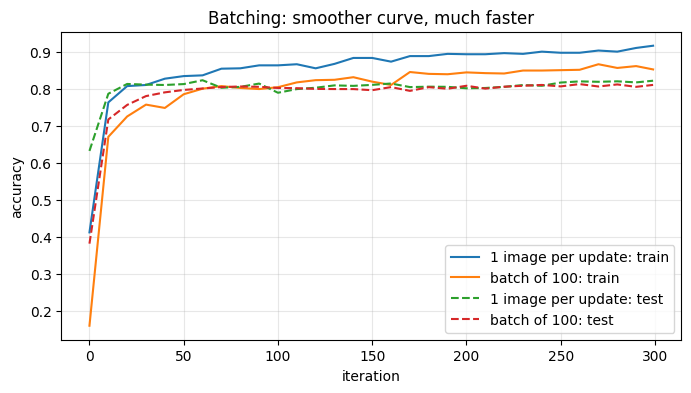

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(log_drop["it"],  log_drop["train_acc"],  label="1 image per update: train")
plt.plot(log_batch["it"], log_batch["train_acc"], label="batch of 100: train")
plt.plot(log_drop["it"],  log_drop["test_acc"],  "--", label="1 image per update: test")
plt.plot(log_batch["it"], log_batch["test_acc"], "--", label="batch of 100: test")
plt.xlabel("iteration"); plt.ylabel("accuracy"); plt.title("Batching: smoother curve, much faster"); plt.legend(); plt.grid(alpha=.3); plt.show()

The batched training curve is **smoother**, because averaging gradients removes much of the per-example noise, and it runs far faster, while reaching a similar test accuracy.

---
## Summary

- **Overfitting**: the network memorizes noise; **test accuracy** (on unseen data) is the score that matters.
- **Regularization** makes it harder to learn fine detail: **early stopping** (stop when a *validation* score stops improving) and **dropout** (randomly zero hidden nodes; multiply survivors by 1/keep-probability).
- Dropout works like training and averaging many small networks (**ensembling**).
- **Mini-batching** averages updates over several examples: faster, smoother, and it tolerates a bigger alpha.
- Next: activation functions (Chapter 9) and special architectures (Chapter 10).